# Predição de risco de diabetes — ODS 3
Projeto de Mineração de Dados · Base: *Diabetes Health Indicators* (BRFSS 2015, CDC) · Metodologia: CRISP-DM

In [1]:
import sys, json
sys.path.insert(0, '../src')
import pandas as pd, numpy as np, joblib
from IPython.display import Image, display
from diabetes_ods.config import *
from diabetes_ods.data import load_data, clean, quality_report
from diabetes_ods.mining import rules_for_diabetes, clusters
from diabetes_ods.train import split
pd.options.display.float_format = '{:.3f}'.format

## 1. Entendimento do problema e CRISP-DM
**Negócio:** o diabetes sobrecarrega sistemas de saúde e atinge mais quem tem menos renda e escolaridade. Um modelo de triagem ajuda a priorizar exames e prevenção.

**ODS:** 3 (principal), 10 (desigualdade), 2 (alimentação); 1 e 4 como ligações secundárias.

**Pergunta:** quais hábitos e condições socioeconômicas mais influenciam o risco, e dá para triar populações vulneráveis?

**Meta de mineração:** classificar pré-diabetes/diabetes (1) vs. sem diabetes (0), priorizando **recall** (não perder casos), já que é uma triagem.

## 2. Aquisição, qualidade e preparação dos dados

In [2]:
raw = load_data()
print(quality_report(raw))
df = clean(raw)
print('Após limpeza:', df.shape, '| prevalência:', round(df[TARGET].mean(), 4))
df.describe().T[['mean','min','max']]

{'linhas': 253680, 'colunas': 22, 'nulos': 0, 'duplicadas': 24206, 'prevalencia_alvo': 0.13933301797540207}


Após limpeza: (229474, 22) | prevalência: 0.1529


,mean,min,max
Diabetes_binary,0.153,0.000,1.000
HighBP,0.454,0.000,1.000
HighChol,0.442,0.000,1.000
CholCheck,0.959,0.000,1.000
BMI,28.688,12.000,98.000
Smoker,0.466,0.000,1.000
Stroke,0.045,0.000,1.000
HeartDiseaseorAttack,0.103,0.000,1.000
PhysActivity,0.733,0.000,1.000
Fruits,0.613,0.000,1.000


**Achados:** sem nulos, mas **24.206 linhas duplicadas** (9,5%), removidas. A prevalência sobe de 13,9% para 15,3% após a remoção. A classe positiva é minoritária, então accuracy seria enganosa.

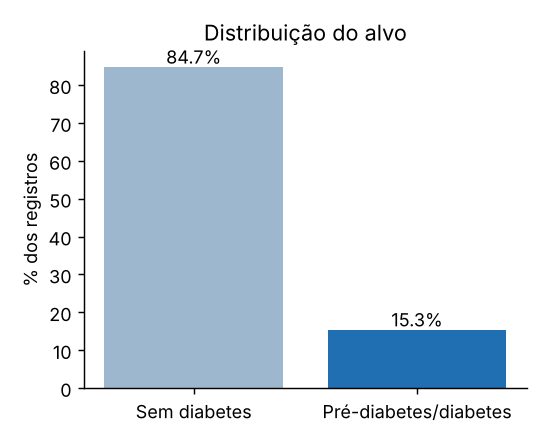

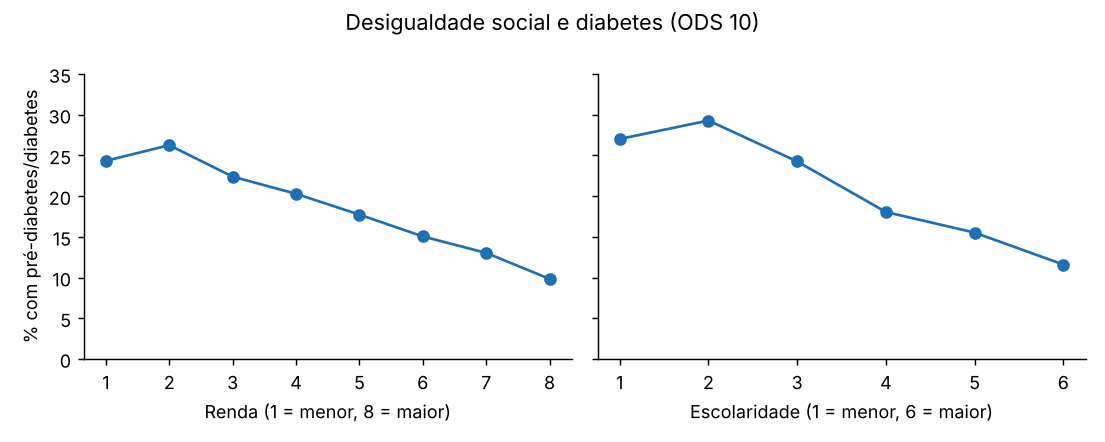

In [3]:
display(Image('../reports/figures/01_alvo.png'))
display(Image('../reports/figures/02_desigualdade.png'))

## 3. Mineração e modelagem
Split 80/20 estratificado (seed 42). Modelos: baseline, regressão logística, random forest e gradient boosting, todos em `Pipeline` (sem vazamento de dados).

In [4]:
m = json.load(open('../reports/metrics.json'))
pd.DataFrame(m['modelos']).T

,recall,precisao,f1,roc_auc,pr_auc
Baseline (classe majoritária),0.000,0.000,0.000,0.500,0.153
Regressão Logística,0.760,0.318,0.449,0.811,0.412
Random Forest,0.743,0.333,0.460,0.817,0.442
Gradient Boosting,0.797,0.317,0.453,0.819,0.446


**Balanceamento:** comparação de estratégias com regressão logística.

In [5]:
pd.DataFrame(m['balanceamento']).T

,recall,precisao,f1,roc_auc,pr_auc
Sem tratamento,0.154,0.541,0.240,0.810,0.414
Pesos de classe,0.760,0.318,0.449,0.811,0.412
Subamostragem,0.757,0.318,0.448,0.810,0.412
SMOTE,0.758,0.319,0.449,0.808,0.408


Sem tratamento o recall cai para ~15%. Pesos de classe, subamostragem e SMOTE ficam praticamente empatados, então usamos **pesos de classe** (mais simples e sem criar dados sintéticos).

### Regras de associação (Apriori) e clusters (K-Means)

In [6]:
rules_for_diabetes(df).head(8)

,regra,support,confidence,lift
0,Obesidade_IMC>=30 + Pressao_alta + Saude_geral...,0.033,0.483,3.160
1,Colesterol_alto + Pressao_alta + Saude_geral_r...,0.038,0.451,2.946
2,Dificuldade_andar + Obesidade_IMC>=30 + Pressa...,0.032,0.448,2.929
3,Dificuldade_andar + Pressao_alta + Saude_geral...,0.031,0.427,2.794
4,Colesterol_alto + Dificuldade_andar + Pressao_...,0.036,0.426,2.788
5,Obesidade_IMC>=30 + Saude_geral_ruim(4-5),0.039,0.423,2.768
6,Idade>=60 + Pressao_alta + Saude_geral_ruim(4-5),0.034,0.419,2.742
7,Colesterol_alto + Saude_geral_ruim(4-5),0.045,0.404,2.643


In [7]:
clusters(df)

,n,prevalencia,imc,idade,renda,escolaridade,saude_geral,pressao_alta,atividade
cluster,,,,,,,,,
0,75385,0.031,26.725,5.884,6.708,5.309,2.000,0.053,0.880
1,41692,0.249,29.895,9.205,3.802,4.156,3.267,0.673,1.000
2,61811,0.157,28.477,9.234,7.061,5.489,2.347,0.651,0.973
3,50586,0.250,30.874,9.037,4.956,4.546,3.262,0.631,0.000


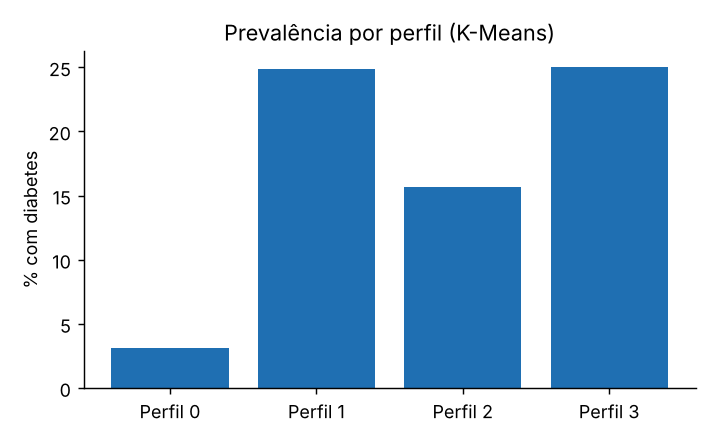

In [8]:
display(Image('../reports/figures/06_clusters.png'))

## 4. Avaliação e interpretação dos resultados

In [9]:
print('Campeão:', m['campeao'], '| limiar de triagem:', m['limiar_triagem'])
pd.Series(m['campeao_limiar_triagem'])

Campeão: Gradient Boosting | limiar de triagem: 0.47


recall     0.822
precisao   0.305
f1         0.445
roc_auc    0.819
pr_auc     0.446
dtype: float64

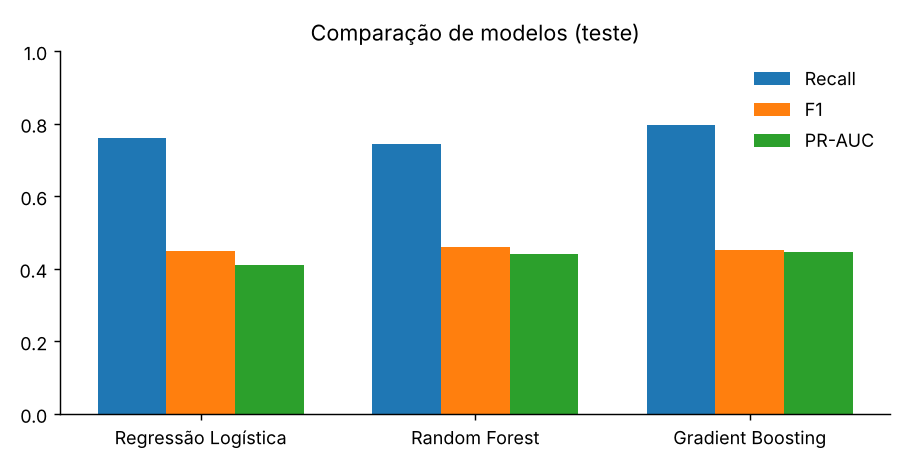

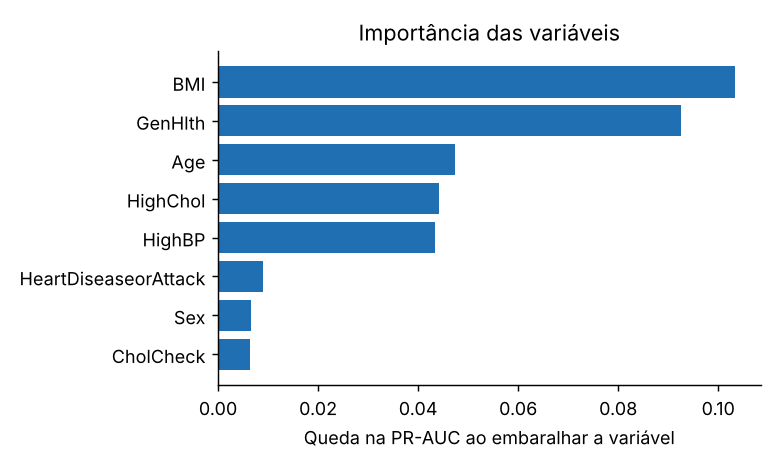

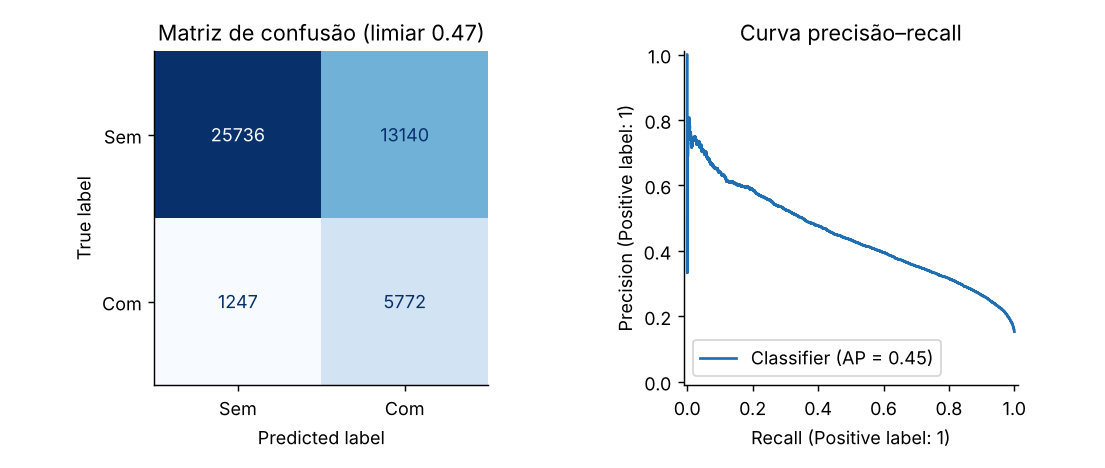

In [10]:
display(Image('../reports/figures/03_modelos.png'))
display(Image('../reports/figures/04_importancia.png'))
display(Image('../reports/figures/05_avaliacao.png'))

**Interpretação:**
- O **Gradient Boosting** teve a melhor PR-AUC; o limiar 0,47 (escolhido em validação) leva o recall a ~82%.
- Isso tem custo: a **precisão fica em ~31%**, ou seja, cerca de 7 em cada 10 alertas são falsos positivos. Para triagem (confirmada depois por exame de glicemia) é aceitável; como diagnóstico, não.
- Variáveis mais importantes: **IMC, saúde geral autorreferida, idade, colesterol e pressão alta**.
- Renda e escolaridade têm efeito próprio menor no modelo, mas a prevalência cai de ~24–29% nas faixas mais baixas para ~10–12% nas mais altas (ODS 10).
- **Limitações:** dados de autorrelato (telefone, EUA, 2015), associação não é causalidade, e o modelo não deve ser aplicado a outra população sem validação.

## 5. Engenharia do pipeline
`load → quality_report → clean → split → ColumnTransformer + modelo → métricas → limiar → modelo.joblib + metrics.json`. Cada etapa é uma função em `src/diabetes_ods/` e o pré-processamento vive dentro do `Pipeline`, então treino e inferência usam exatamente a mesma transformação. Reexecute com `make train report`.

## 6. Arquitetura e implementação do software
```
data (CSV) → src/diabetes_ods (data, features, train, mining, report, predict)
          → models/modelo.joblib → app/main.py (FastAPI: /health, /predict) → Docker
```
A API valida entradas com Pydantic (ex.: IMC 10–100, idade em 13 faixas) e devolve probabilidade e alerta de alto risco.

In [11]:
from fastapi.testclient import TestClient
sys.path.insert(0, '..')
from app.main import app
c = TestClient(app)
base = dict(HighBP=1, HighChol=1, BMI=34, PhysActivity=0, GenHlth=4, Sex=0, Age=10, Education=3, Income=2)
print('Perfil de risco:', c.post('/predict', json=base).json())
print('Perfil saudável:', c.post('/predict', json=dict(HighBP=0, HighChol=0, BMI=22, PhysActivity=1, GenHlth=1, Sex=1, Age=3, Education=6, Income=8)).json())

Perfil de risco: {'probabilidade': 0.8683, 'alto_risco': True, 'limiar': 0.47}
Perfil saudável: {'probabilidade': 0.0208, 'alto_risco': False, 'limiar': 0.47}


/usr/local/lib/python3.12/dist-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


## 7. Reprodutibilidade, testes e DevOps
- **Seed fixa** (42) em split e modelos; `requirements.txt` e `Makefile`.
- **8 testes** com pytest (dados, pipeline, limiar e API), todos passando.
- **Dockerfile** para empacotar a API e **GitHub Actions** (`.github/workflows/ci.yml`) rodando testes e build a cada push.
- Os dados não vão ao repositório (`.gitignore`); o README explica como baixar do Kaggle.

In [12]:
import subprocess
r = subprocess.run(['python', '-m', 'pytest', '-q', '..'], capture_output=True, text=True, env={**__import__('os').environ, 'PYTHONPATH': '../src'}, cwd='..')
print(r.stdout[-300:])

ing: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
    from starlette.testclient import TestClient as TestClient  # noqa

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
8 passed, 1 warning in 1.80s



## 8. Apresentação e demonstração
Roteiro: problema e ODS → dados e qualidade → modelagem → resultados (recall vs. precisão) → demo da API (`/predict`) → limitações e próximos passos (calibração, validação externa, dados brasileiros como a PNS).